# **Exploratory Data Analysis (EDA) with the Sales Dataset using Pandas and d Matplotlib/Seaborn**

### **Objective:**

The goal is to  apply my knowledge of Python for basic operations, Pandas for data manipulation, and Matplotlib/Seaborn for visualizations. I'll be working with a real-world dataset, and my tasks will include loading the data, performing EDA, and visualising the results.

###  **Dataset**

The dataset represents transaction data from a retail business, specifically sales data for products sold in various stores. It contains multiple tables that provide insights into sales, invoices, and products. Let’s break down the tables and what they represent:

#### Sales Table:

InvoiceNo: The unique identifier for each invoice (or transaction).

StockCode: A unique identifier for each product.

Quantity: The number of units sold in each transaction.

UnitPrice: The price per unit of the product.

InvoiceDate: The date when the transaction occurred.

#### Invoice Table:

InvoiceNo: The same unique identifier for each invoice, linking the sales data with the invoice details.

Country: The country where the sale was made.

#### Product Table:

StockCode: A unique identifier for each product.

Description: The name or description of the product.

Product_Category: The category the product belongs to (e.g., "Gift", "Sign", "Mug").



I will need to merge them and perform the following tasks step by step.


### Task 1: Load the Excel File
#### Objective: Import the data from the provided Excel file into Python using Pandas.

Instructions:

1. Upload the provided excel file into Fabric environment
2. Read each sheet of the excel file as a separate dataframe. 
3. Name the dataframe for sales as df_sales, the dataframe for invoice as df_invoice and the dataframe for product as df_product
4. Display the first few rows of each DataFrame to understand its structure.



In [23]:
### Code Task Here
import pandas as pd

df_sales= pd.read_excel("data/Online Sales Retailer.xlsx", sheet_name="Sales")


df_invoice = pd.read_excel("data/Online Sales Retailer.xlsx", sheet_name= 'Invoice')

df_product = pd.read_excel("data/Online Sales Retailer.xlsx", sheet_name= 'Product')

# Display the first few rows of each DataFrame
display(df_sales.head())
display(df_invoice.head())
display(df_product.head())


,InvoiceNo,StockCode,Quantity,UnitPrice,InvoiceDate
0,536365,71053,6,3.39,2015-01-01
1,536365,22752,2,7.65,2015-01-01
2,536365,84406,8,2.75,2015-01-01
3,536366,84029,6,3.39,2015-01-01
4,536366,21730,6,4.25,2015-01-01


,InvoiceNo,Country
0,536365,United Kingdom
1,536366,United Kingdom
2,536367,United Kingdom
3,536368,United Kingdom
4,536369,United Kingdom


,StockCode,Description,Product_Category
0,71053,PHOTO FRAME CORNICE,FRAME
1,22752,TEA TIME TEAPOT IN GIFT BOX,GIFT
2,84406,ZINC HEARTS PLANT POT HOLDER,HOLDER
3,84029,FRENCH BLUE METAL DOOR SIGN 3,SIGN
4,21730,CERAMIC CAKE DESIGN SPOTTED MUG,MUG


### Task 2: Basic Python and Pandas Operations
#### Objective: Perform basic Python and Pandas operations to manipulate the data.

<mark>Instructions:</mark>

1. Create the Sales Column (Quantity * Unit Price) 

2. Check for missing values in the Sales DataFrame.

3. Replace any NaN values in the Sales and UnitPrice columns with 0.

4. Calculate basic descriptive statistics for the Quantity and UnitPrice columns (mean, median, mode, standard deviation).

In [24]:
## Code Task 2 here
## Create the Sales Column (Quantity * Unit Price)
df_sales['Sales']= df_sales ['Quantity']*df_sales['UnitPrice']
display(df_sales.head())

,InvoiceNo,StockCode,Quantity,UnitPrice,InvoiceDate,Sales
0,536365,71053,6,3.39,2015-01-01,20.34
1,536365,22752,2,7.65,2015-01-01,15.30
2,536365,84406,8,2.75,2015-01-01,22.00
3,536366,84029,6,3.39,2015-01-01,20.34
4,536366,21730,6,4.25,2015-01-01,25.50


In [25]:
## Check for missing values in the Sales DataFrame.
missing_values = df_sales.isnull()

rows_with_nulls = df_sales[missing_values.any(axis=1)]

display(rows_with_nulls)

,InvoiceNo,StockCode,Quantity,UnitPrice,InvoiceDate,Sales


In [26]:
## Replace any NaN values in the Sales and UnitPrice columns with 0
df_sales.fillna(0, inplace=True)

display(df_sales.head())

,InvoiceNo,StockCode,Quantity,UnitPrice,InvoiceDate,Sales
0,536365,71053,6,3.39,2015-01-01,20.34
1,536365,22752,2,7.65,2015-01-01,15.30
2,536365,84406,8,2.75,2015-01-01,22.00
3,536366,84029,6,3.39,2015-01-01,20.34
4,536366,21730,6,4.25,2015-01-01,25.50


In [27]:
## Calculate basic descriptive statistics for the Quantity and UnitPrice columns (mean, median, mode, standard deviation)

mean_unitprice = df_sales['UnitPrice'].mean().round(2)
median_unitprice = df_sales['UnitPrice'].median()
mode_unitprice = df_sales['UnitPrice'].mode()[0] 
std_unitprice = df_sales['UnitPrice'].std()


mean_quantity = df_sales['Quantity'].mean().round(2)
median_quantity = df_sales['Quantity'].median()
mode_quantity = df_sales['Quantity'].mode()[0]
std_quantity = df_sales['Quantity'].std()


print(f"UnitPrice - Average Sales: {mean_unitprice}, Median Sales: {median_unitprice}, Mode: {mode_unitprice}, Std Dev: {std_unitprice}")
print(f"Quantity - Mean: {mean_quantity}, Median: {median_quantity}, Mode: {mode_quantity}, Std Dev: {std_quantity}")

UnitPrice - Average Sales: 3.08, Median Sales: 1.95, Mode: 1.25, Std Dev: 5.17765256537552
Quantity - Mean: 13.61, Median: 6.0, Mode: 1, Std Dev: 261.57756533193884


### Task 3: Merging DataFrames
#### Objective: Merge the Sales, Invoice, and Product tables based on common keys to perform a comprehensive analysis.

Instructions:

1. Merge the Sales DataFrame with the Invoice DataFrame on InvoiceNo.

2. Merge the result with the Product DataFrame on StockCode

In [28]:
## Code Task 3 here
## Merge the Sales DataFrame with the Invoice DataFrame on InvoiceNo
df_sales_combined = pd.merge(df_sales, df_invoice, on='InvoiceNo')


display(df_sales_combined.head())


,InvoiceNo,StockCode,Quantity,UnitPrice,InvoiceDate,Sales,Country
0,536365,71053,6,3.39,2015-01-01,20.34,United Kingdom
1,536365,22752,2,7.65,2015-01-01,15.30,United Kingdom
2,536365,84406,8,2.75,2015-01-01,22.00,United Kingdom
3,536366,84029,6,3.39,2015-01-01,20.34,United Kingdom
4,536366,21730,6,4.25,2015-01-01,25.50,United Kingdom


In [29]:
## Merge the result with the Product DataFrame on StockCode
df_product_combined = pd.merge(df_sales_combined, df_product, on='StockCode')
display(df_product_combined.head())

,InvoiceNo,StockCode,Quantity,UnitPrice,InvoiceDate,Sales,Country,Description,Product_Category
0,536365,71053,6,3.39,2015-01-01,20.34,United Kingdom,PHOTO FRAME CORNICE,FRAME
1,536365,22752,2,7.65,2015-01-01,15.30,United Kingdom,TEA TIME TEAPOT IN GIFT BOX,GIFT
2,536365,84406,8,2.75,2015-01-01,22.00,United Kingdom,ZINC HEARTS PLANT POT HOLDER,HOLDER
3,536366,84029,6,3.39,2015-01-01,20.34,United Kingdom,FRENCH BLUE METAL DOOR SIGN 3,SIGN
4,536366,21730,6,4.25,2015-01-01,25.50,United Kingdom,CERAMIC CAKE DESIGN SPOTTED MUG,MUG


## Task 4: Exploratory Data Analysis (EDA)
### Objective: Conduct EDA by analysing the data, identifying patterns, trends, and outliers.

Instructions:

Use describe() to calculate summary statistics for numeric columns.

Perform basic filtering, such as filtering out sales with Quantity equal to 0.

Check for outliers in the Sales column by using a scatter plot.

In [30]:
## Code Task 4 here
## Use describe() to calculate summary statistics for numeric columns.
df_product_combined[['Quantity','Sales','UnitPrice']].describe().round(2)


,Quantity,Sales,UnitPrice
count,83277.00,83277.00,83277.00
mean,13.61,23.12,3.08
std,261.58,278.04,5.18
min,1.00,0.00,0.00
25%,2.00,5.00,1.25
50%,6.00,12.50,1.95
75%,12.00,19.50,3.75
max,74215.00,77183.60,295.00


In [31]:
## Perform basic filtering, such as filtering out sales with Quantity equal to 0.
df_filtered=df_product_combined[df_product_combined['Quantity']==0]
display(df_filtered)


,InvoiceNo,StockCode,Quantity,UnitPrice,InvoiceDate,Sales,Country,Description,Product_Category


In [32]:
## Create new Column 'Year' for visualisation using 'Sales' and 'Year'
df_product_combined['Year'] = df_product_combined['InvoiceDate'].dt.strftime('%Y')
display(df_product_combined.head())

,InvoiceNo,StockCode,Quantity,UnitPrice,InvoiceDate,Sales,Country,Description,Product_Category,Year
0,536365,71053,6,3.39,2015-01-01,20.34,United Kingdom,PHOTO FRAME CORNICE,FRAME,2015
1,536365,22752,2,7.65,2015-01-01,15.30,United Kingdom,TEA TIME TEAPOT IN GIFT BOX,GIFT,2015
2,536365,84406,8,2.75,2015-01-01,22.00,United Kingdom,ZINC HEARTS PLANT POT HOLDER,HOLDER,2015
3,536366,84029,6,3.39,2015-01-01,20.34,United Kingdom,FRENCH BLUE METAL DOOR SIGN 3,SIGN,2015
4,536366,21730,6,4.25,2015-01-01,25.50,United Kingdom,CERAMIC CAKE DESIGN SPOTTED MUG,MUG,2015


In [33]:
## Install seaborn matplotlib

%pip install seaborn matplotlib




Note: you may need to restart the kernel to use updated packages.


In [34]:
import matplotlib.pyplot as plt
import seaborn as sns

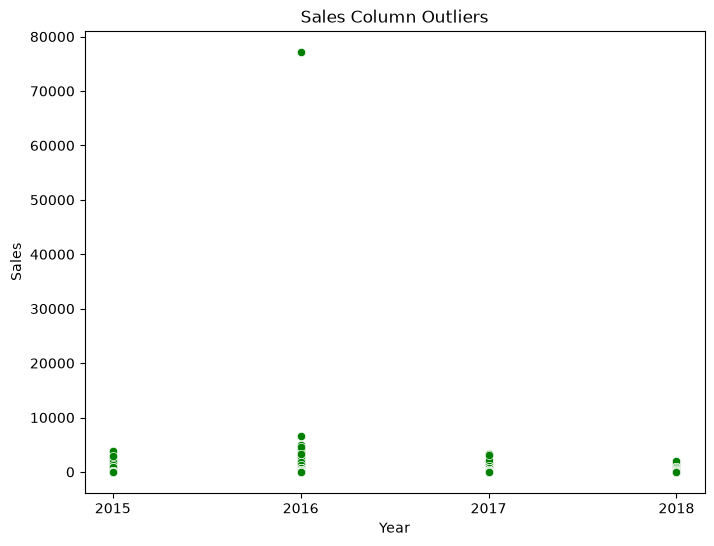

In [35]:
## Check for outliers in the Sales column by using a scatter plot.

plt.figure(figsize=(8, 6))

sns.scatterplot(x='Year', y='Sales', data=df_product_combined, color='green')
plt.title('Sales Column Outliers')
plt.xlabel('Year')
plt.ylabel('Sales')
plt.show()



## Task 5: Data Visualisation – Scatter Plot, Histogram, and Line Chart
### Objective: Create scatter plots, histograms, and line charts to better understand the data.

Instructions:

Use a scatter plot to examine the relationship between Quantity and Sales.

Use a histogram to visualise the distribution of the Sales column.

Use a line chart to show the trend of Sales over time.

Write 1–2 sentences explaining the insights from each visualisation.

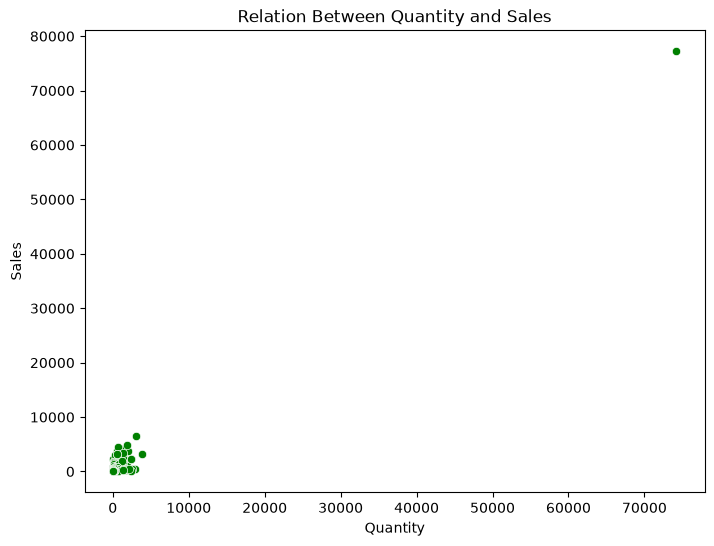

In [36]:
## Use a scatter plot to examine the relationship between Quantity and Sales.
plt.figure(figsize=(8, 6))

sns.scatterplot(x='Quantity', y='Sales',data= df_product_combined, color='green')

plt.title('Relation Between Quantity and Sales')
plt.xlabel('Quantity')
plt.ylabel('Sales')
plt.show()

This scatter plot is showing relation between quantity and sales. Most of the points are at lower level showing small quantity and sales. Its showing small orders. One outlier can be seen where quantity and sales are higher than 70K. It could be a one big order or a bulk order.


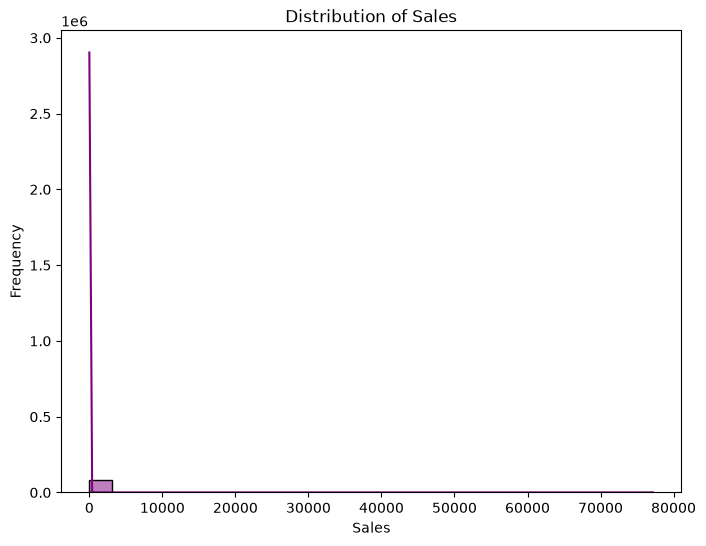

In [37]:
## Use a histogram to visualise the distribution of the Sales column.

plt.figure(figsize=(8, 6))
sns.histplot(df_product_combined['Sales'], bins=25, color='purple', kde=True)
plt.title('Distribution of Sales')
plt.xlabel('Sales')
plt.ylabel('Frequency')
plt.show()

The histogram shows the data from sales column which is highly slanted. Most transactions are of low values, but some showing extremely high value.

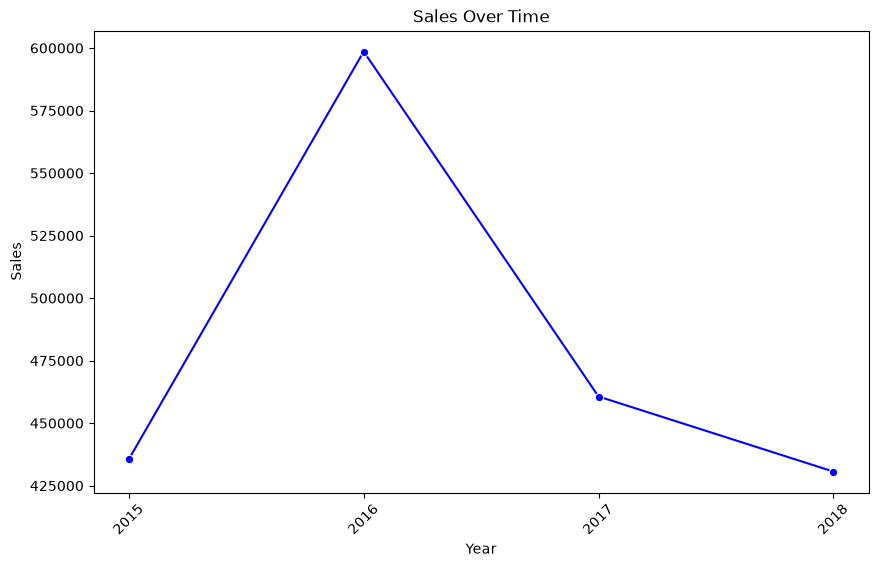

In [38]:
## Use a line chart to show the trend of Sales over time
plt.figure(figsize=(10, 6))

df_product_combined= df_product_combined.groupby('Year')['Sales'].sum().reset_index()


sns.lineplot(x='Year', y='Sales', data= df_product_combined, marker='o', color='blue')
plt.title('Sales Over Time')
plt.xlabel('Year')
plt.ylabel('Sales')
plt.xticks(rotation=45)
plt.show()

This line chart shows sales over time. It is clearly seen that sales increased significantly from 2015 to 2016, then keep on declining through 2017 and 2018. Peak sales in 2016 was nearly 600K.It clearly shows that 2016 was the year where it has sales outliers with a big order.

## Task 6: Correlation and Data Insights
### Objective: Identify the relationship between different numerical columns in the dataset.

Instructions:

Calculate the correlation between Quantity and Sales.

Visualise the correlation matrix using a heatmap.

Write 1–2 sentences explaining the insights from the visualisation.

In [39]:
## Define df_product_combined again to load all categories
df_product_combined = pd.merge(df_sales_combined, df_product, on='StockCode')
display(df_product_combined.head())

,InvoiceNo,StockCode,Quantity,UnitPrice,InvoiceDate,Sales,Country,Description,Product_Category
0,536365,71053,6,3.39,2015-01-01,20.34,United Kingdom,PHOTO FRAME CORNICE,FRAME
1,536365,22752,2,7.65,2015-01-01,15.30,United Kingdom,TEA TIME TEAPOT IN GIFT BOX,GIFT
2,536365,84406,8,2.75,2015-01-01,22.00,United Kingdom,ZINC HEARTS PLANT POT HOLDER,HOLDER
3,536366,84029,6,3.39,2015-01-01,20.34,United Kingdom,FRENCH BLUE METAL DOOR SIGN 3,SIGN
4,536366,21730,6,4.25,2015-01-01,25.50,United Kingdom,CERAMIC CAKE DESIGN SPOTTED MUG,MUG


          Quantity     Sales
Quantity  1.000000  0.978609
Sales     0.978609  1.000000


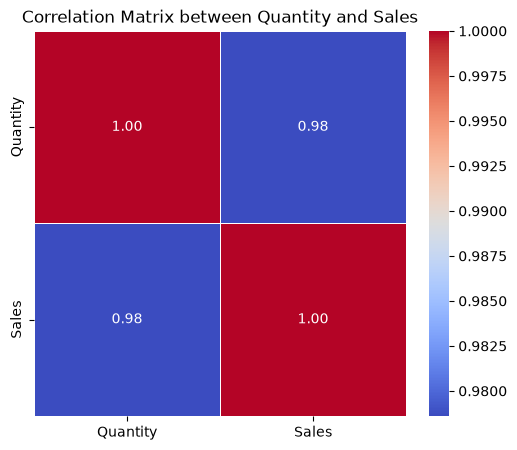

In [40]:
# Calculate correlation between 'Quantity' and 'Sales'
correlation = df_product_combined[['Quantity', 'Sales']].corr()

print(correlation)

plt.figure(figsize=(6, 5))
sns.heatmap(correlation, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Correlation Matrix between Quantity and Sales')
plt.show()

This heatmap shows very strong correlation between Quantity and sales. Sales and Quantity sold increased together. The outlier seen in the previous visuals can effect this relationship.

## Task 7: Grouping and Aggregating
### Objective: Perform grouping and aggregation operations to summarise the data.

Instructions:

GroupBy operation: Group by Product_Category and calculate the total Sales per category.

Create a Pivot Table to show Sales by Country and Product_Category.

In [41]:
## GroupBy operation: Group by Product_Category and calculate the total Sales per category.
sales_by_category = df_product_combined.groupby('Product_Category')['Sales'].sum().reset_index()

display(sales_by_category)


,Product_Category,Sales
0,APRON,3858.13
1,BACKPACK,97.30
2,BADGES,2415.15
3,BAG,45694.01
4,BALLOONS,297.12
...,...,...
165,WINDMILL,201.64
166,WOOD LETTERS,3126.40
167,WOODEN,311.75
168,WRAP,24542.26


In [42]:
## Create a Pivot Table to show Sales by Country and Product_Category.
pivot_table = df_product_combined.pivot_table(values='Sales', index='Country', columns='Product_Category', aggfunc='sum')

pivot_table = pivot_table.reset_index()
pivot_table.fillna(0, inplace=True)

display((pivot_table).head())


Product_Category,Country,APRON,BACKPACK,BADGES,BAG,BALLOONS,BAND,BANGLE,BASKET,BEAD,...,TUBE,UMBRELLA,Uncategorized,WARMER,WATERING,WINDMILL,WOOD LETTERS,WOODEN,WRAP,WRITING
0,AUS,0.00,0.0,0.00,15.60,0.00,0.0,0.0,0.00,0.00,...,0.00,0.0,10.50,0.0,0.00,0.0,0.0,0.0,0.00,0.0
1,Australia,0.00,0.0,0.00,188.56,10.08,0.0,0.0,0.00,23.80,...,14.85,0.0,488.31,0.0,142.50,0.0,0.0,0.0,29.50,25.5
2,Austria,0.00,0.0,0.00,58.18,0.00,0.0,0.0,0.00,0.00,...,0.00,0.0,111.16,0.0,0.00,0.0,0.0,0.0,15.60,0.0
3,Bahrain,0.00,0.0,0.00,0.00,0.00,0.0,0.0,0.00,0.00,...,0.00,0.0,46.65,0.0,0.00,0.0,0.0,0.0,0.00,0.0
4,Belgium,45.27,0.0,17.85,206.74,0.00,0.0,0.0,18.85,31.76,...,0.00,30.0,959.01,22.5,4.95,0.0,0.0,0.0,213.76,0.0
